Wszystkie biblioteki zostały załadowane.

KORPUS
Liczba zdań: 60
Budowla: 20
Mechanizm: 20
Zamek błyskawiczny: 20

3. PORÓWNANIE TOKENIZACJI BPE

BPE – limit słownika: 50
Rzeczywisty rozmiar słownika: 50
zamek        -> ['z', 'am', 'ek']
zamku        -> ['z', 'am', 'k', 'u']
zamkiem      -> ['z', 'am', 'k', 'i', 'e', 'm']
zamki        -> ['z', 'am', 'k', 'i']
zamkami      -> ['z', 'am', 'k', 'am', 'i']
zamkach      -> ['z', 'am', 'k', 'a', 'c', 'h']
Średnia liczba tokenów: 4.67

BPE – limit słownika: 100
Rzeczywisty rozmiar słownika: 100
zamek        -> ['zamek']
zamku        -> ['zamku']
zamkiem      -> ['zam', 'k', 'ie', 'm']
zamki        -> ['zam', 'k', 'i']
zamkami      -> ['zam', 'k', 'am', 'i']
zamkach      -> ['zam', 'ka', 'ch']
Średnia liczba tokenów: 2.67

BPE – limit słownika: 150
Rzeczywisty rozmiar słownika: 150
zamek        -> ['zamek']
zamku        -> ['zamku']
zamkiem      -> ['zam', 'kie', 'm']
zamki        -> ['zam', 'ki']
zamkami      -> ['zam', 'k', 'am', 'i']
zamkac

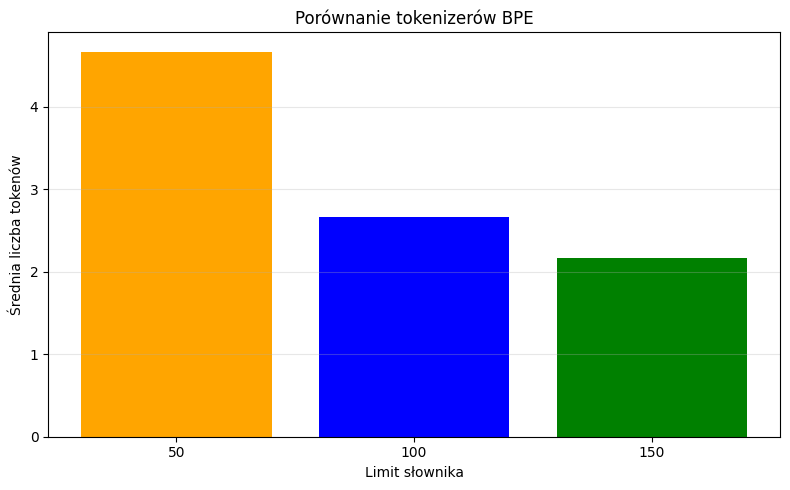


4. PORÓWNANIE WORD2VEC

 WARIANT A
Najbliżsi sąsiedzi słowa ZAMEK:
się                  0.9954
funkcję              0.9953
w                    0.9951
znajdowała           0.9951
pełnił               0.9943
najeźdźcami          0.9943
wakacji              0.9942
kurtki               0.9942
przedmiotów          0.9942
fosa                 0.9941

 WARIANT B
Najbliżsi sąsiedzi słowa ZAMEK:
się                  0.9955
w                    0.9953
mogę                 0.9949
wzgórzu              0.9949
bardzo               0.9948
nie                  0.9946
zamka                0.9944
kodu                 0.9942
interesująca         0.9941
szkole               0.9941

5. WIZUALIZACJA PCA


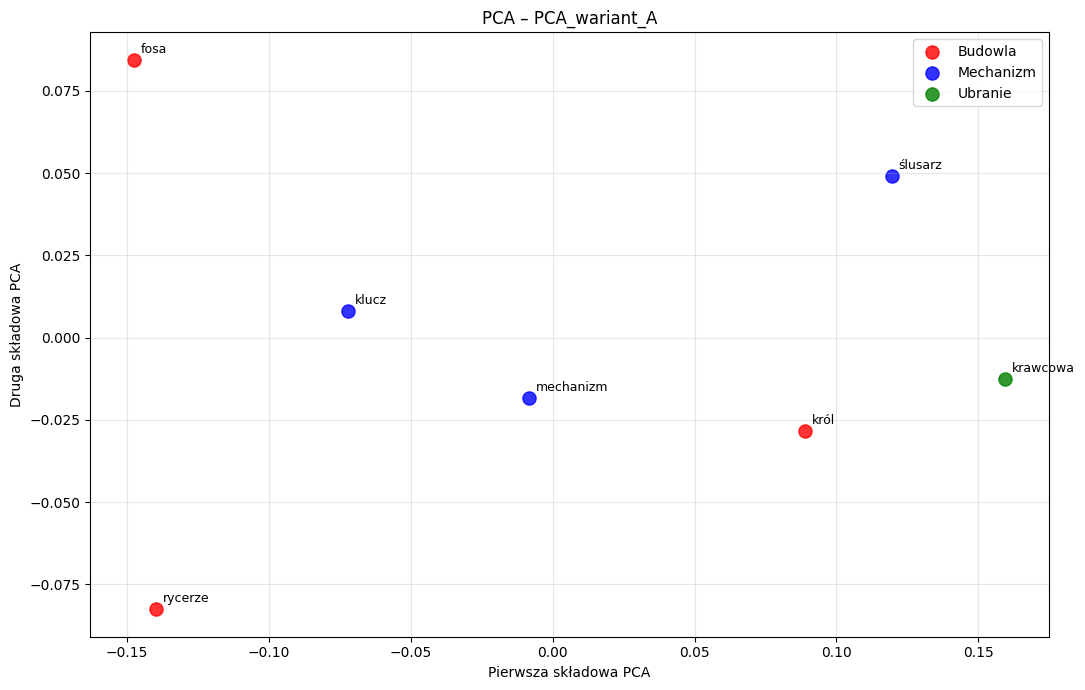

Zapisano wykres: PCA_wariant_A.png
Wyjaśniona wariancja PCA: 74.59 %


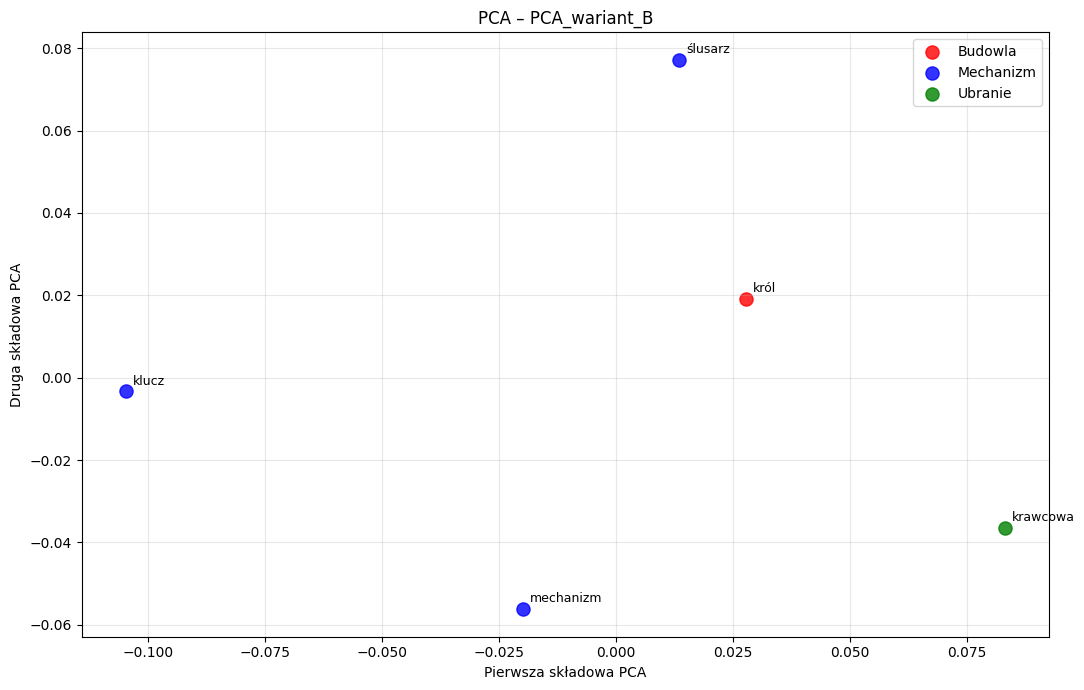

Zapisano wykres: PCA_wariant_B.png
Wyjaśniona wariancja PCA: 63.86 %

PODSUMOWANIE EKSPERYMENTU

1. BPE:
   Porównano trzy rozmiary słownika.
   Sprawdzono podział sześciu form słowa zamek.

2. Word2Vec:
   Wytrenowano dwa modele na różnych proporcjach znaczeń.
   Sprawdzono 10 najbliższych sąsiadów słowa zamek.

3. PCA:
   Wykonano wizualizację trzech grup tematycznych.
   Wygenerowano dwa wykresy.

4. Korpus:
   Wykorzystano 60 zdań autorskich.
   Każde znaczenie reprezentowane jest przez 20 zdań.

Eksperyment zakończony!

Wszystkie etapy wykonane.


In [5]:

# ============================================================
# PROJEKT NLP – WIELOZNACZNOŚĆ SŁOWA "ZAMEK"
# BPE + Word2Vec + PCA
# ============================================================

# 1. INSTALACJA BIBLIOTEK
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "tokenizers", "gensim", "scikit-learn",
    "matplotlib", "numpy"
])

import re
import numpy as np
import matplotlib.pyplot as plt

from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

print("Wszystkie biblioteki zostały załadowane.")

# ============================================================
# 2. PRZYGOTOWANIE KORPUSU – 60 ZDAŃ
# ============================================================

# ZNACZENIE 1 – ZAMEK JAKO BUDOWLA

budowla = [
    "Zamek królewski znajduje się na wzgórzu.",
    "Turyści zwiedzali stary zamek.",
    "W średniowieczu zamek pełnił funkcję obronną.",
    "Król mieszkał w pięknym zamku.",
    "Wokół zamku znajdowała się głęboka fosa.",
    "Rycerze bronili zamku przed najeźdźcami.",
    "Zamek został zbudowany w trzynastym wieku.",
    "Wnętrze zamku było bogato zdobione.",
    "Podczas wakacji odwiedziliśmy zamek w Malborku.",
    "Przewodnik opowiadał historię zamku.",
    "Na szczycie zamku powiewała flaga.",
    "Zamek posiadał wysokie wieże i grube mury.",
    "Władca rozkazał rozbudować zamek.",
    "W pobliżu zamku znajdował się park.",
    "Dawny zamek został przekształcony w muzeum.",
    "Mieszkańcy miasta podziwiali piękny zamek.",
    "W zamku organizowano wystawy historyczne.",
    "Archeolodzy odkryli ruiny starego zamku.",
    "Zamek był otoczony kamiennym murem.",
    "Dzieci słuchały legend o zaczarowanym zamku."
]

# ZNACZENIE 2 – ZAMEK W DRZWIACH

mechanizm = [
    "Zamek w drzwiach przestał działać.",
    "Ślusarz naprawił uszkodzony zamek.",
    "Klucz pasuje do zamka w mieszkaniu.",
    "Zamek w samochodzie został wymieniony.",
    "Nie mogę otworzyć zamka bez klucza.",
    "Złodziej próbował wyłamać zamek.",
    "Nowy zamek zapewnia większe bezpieczeństwo.",
    "Mechanizm zamka wymagał konserwacji.",
    "Zamek w furtce był zardzewiały.",
    "Ojciec zamontował zamek w drzwiach.",
    "Klucz utknął w zamku.",
    "Elektroniczny zamek otwiera się za pomocą kodu.",
    "Wymieniłem zamek w garażu.",
    "Zamek nie reagował na przekręcanie klucza.",
    "Ślusarz dokładnie sprawdził zamek.",
    "Drzwi miały dodatkowy zamek antywłamaniowy.",
    "Zamek w szafce był uszkodzony.",
    "Zabezpieczyliśmy drzwi solidnym zamkiem.",
    "W starym domu każdy zamek wymagał naprawy.",
    "Nowoczesny zamek posiada elektroniczny czytnik."
]

# ZNACZENIE 3 – ZAMEK BŁYSKAWICZNY

suwak = [
    "Zamek w kurtce zepsuł się podczas spaceru.",
    "Krawcowa wymieniła zamek w spodniach.",
    "Zamek błyskawiczny nie chciał się zapiąć.",
    "W mojej bluzie znajduje się metalowy zamek.",
    "Zamek w torbie zaciął się.",
    "Muszę kupić nowy zamek do kurtki.",
    "Dziewczynka rozsunęła zamek w plecaku.",
    "Zamek w sukience był ukryty z tyłu.",
    "Krawiec przyszył zamek do materiału.",
    "Plastikowy zamek jest lekki i wygodny.",
    "Zamek w śpiworze działał bez zarzutu.",
    "Zepsuty zamek utrudniał zamykanie torby.",
    "Kurtka miała długi metalowy zamek.",
    "Zamek w butach sportowych był uszkodzony.",
    "Rozpiąłem zamek w bluzie.",
    "Nowy zamek został wszyty przez krawcową.",
    "Zamek błyskawiczny składa się z dwóch rzędów ząbków.",
    "Suwak przesuwał się po całej długości zamka.",
    "Zamek w walizce był bardzo wytrzymały.",
    "Krawcowa dobrała odpowiedni zamek do kurtki."
]

korpus = budowla + mechanizm + suwak

print("\nKORPUS")
print("Liczba zdań:", len(korpus))
print("Budowla:", len(budowla))
print("Mechanizm:", len(mechanizm))
print("Zamek błyskawiczny:", len(suwak))

# ============================================================
# 3. TOKENIZACJA BPE – TRZY ROZMIARY SŁOWNIKA
# ============================================================

print("\n" + "="*55)
print("3. PORÓWNANIE TOKENIZACJI BPE")
print("="*55)

formy = [
    "zamek", "zamku", "zamkiem",
    "zamki", "zamkami", "zamkach"
]

wyniki_bpe = {}

for rozmiar in [50, 100, 150]:

    tokenizer = Tokenizer(
        models.BPE(unk_token="[UNK]")
    )

    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

    trainer = trainers.BpeTrainer(
        vocab_size=rozmiar,
        min_frequency=1,
        special_tokens=["[UNK]"]
    )

    tokenizer.train_from_iterator(korpus, trainer)

    liczby = []

    print(f"\nBPE – limit słownika: {rozmiar}")
    print("Rzeczywisty rozmiar słownika:",
          len(tokenizer.get_vocab()))

    for forma in formy:
        tokeny = tokenizer.encode(forma).tokens
        liczby.append(len(tokeny))

        print(f"{forma:12} -> {tokeny}")

    srednia = np.mean(liczby)
    wyniki_bpe[rozmiar] = srednia

    print("Średnia liczba tokenów:", round(srednia, 2))

print("\nPODSUMOWANIE BPE")
for rozmiar, wynik in wyniki_bpe.items():
    print(f"Słownik {rozmiar}: średnio {wynik:.2f} tokenów")

# Wykres BPE

plt.figure(figsize=(8, 5))
plt.bar(
    [str(x) for x in wyniki_bpe.keys()],
    list(wyniki_bpe.values()),
    color=["orange", "blue", "green"]
)
plt.title("Porównanie tokenizerów BPE")
plt.xlabel("Limit słownika")
plt.ylabel("Średnia liczba tokenów")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("BPE_porownanie.png", dpi=150)
plt.show()

# ============================================================
# 4. WORD2VEC – DWA WARIANTY KORPUSU
# ============================================================

print("\n" + "="*55)
print("4. PORÓWNANIE WORD2VEC")
print("="*55)

# Wariant A: po 8 zdań dla każdego znaczenia

dane_A = (
    budowla[:8] +
    mechanizm[:8] +
    suwak[:8]
)

# Wariant B: 4 zdania budowla,
# 12 zdań mechanizm, 8 zdań suwak

dane_B = (
    budowla[:4] +
    mechanizm[:12] +
    suwak[:8]
)

# Wspólna baza zdań

baza = [
    "Ludzie codziennie korzystają z różnych przedmiotów.",
    "W muzeum można zobaczyć wiele ciekawych eksponatów.",
    "Historia Polski jest bardzo interesująca.",
    "Przedmioty powinny być odpowiednio zabezpieczone.",
    "Wiele osób podróżuje podczas wakacji.",
    "Nowoczesne technologie zmieniają nasze życie.",
    "W warsztacie pracują doświadczeni specjaliści.",
    "Dzieci uczą się nowych rzeczy w szkole."
]

# Zamiana form odmiany na wspólny token "zamek"

odmiany = {
    "zamku", "zamkiem", "zamki",
    "zamkami", "zamkach"
}

def przygotuj_zdania(zestaw):

    wynik = []

    for zdanie in zestaw:

        slowa = re.findall(
            r"[a-ząćęłńóśźż]+",
            zdanie.lower()
        )

        slowa = [
            "zamek" if slowo in odmiany else slowo
            for slowo in slowa
        ]

        wynik.append(slowa)

    return wynik


def trenuj_word2vec(dane):

    tekst = przygotuj_zdania(baza + dane)

    model = Word2Vec(
        sentences=tekst,
        vector_size=50,
        window=4,
        min_count=1,
        workers=1,
        seed=42,
        epochs=200,
        sg=1
    )

    return model


model_A = trenuj_word2vec(dane_A)
model_B = trenuj_word2vec(dane_B)

# Wyświetlenie sąsiadów

for nazwa, model in [
    ("WARIANT A", model_A),
    ("WARIANT B", model_B)
]:

    print("\n", nazwa)
    print("Najbliżsi sąsiedzi słowa ZAMEK:")

    for slowo, wynik in model.wv.most_similar(
        "zamek", topn=10
    ):
        print(f"{slowo:20} {wynik:.4f}")

# ============================================================
# 5. PCA – GRUPY TEMATYCZNE
# ============================================================

print("\n" + "="*55)
print("5. WIZUALIZACJA PCA")
print("="*55)

grupy_slow = {

    "Budowla": [
        "król", "rycerze", "wieże",
        "mury", "fosa"
    ],

    "Mechanizm": [
        "klucz", "drzwi", "ślusarz",
        "mechanizm", "zabezpieczenie"
    ],

    "Ubranie": [
        "kurtka", "suwak", "spodnie",
        "krawcowa", "materiał"
    ]
}

kolory = {
    "Budowla": "red",
    "Mechanizm": "blue",
    "Ubranie": "green"
}


def rysuj_pca(model, nazwa):

    slowa = []
    etykiety = []
    wektory = []

    for grupa, lista in grupy_slow.items():

        for slowo in lista:

            if slowo in model.wv:

                slowa.append(slowo)
                etykiety.append(grupa)
                wektory.append(model.wv[slowo])

    if len(wektory) < 2:
        print("Za mało słów do wykonania PCA.")
        return

    X = np.array(wektory)

    pca = PCA(n_components=2)
    punkty = pca.fit_transform(X)

    plt.figure(figsize=(11, 7))

    for grupa in grupy_slow:

        indeksy = [
            i for i, g in enumerate(etykiety)
            if g == grupa
        ]

        if indeksy:

            plt.scatter(
                punkty[indeksy, 0],
                punkty[indeksy, 1],
                color=kolory[grupa],
                label=grupa,
                s=90,
                alpha=0.8
            )

    for i, slowo in enumerate(slowa):

        plt.annotate(
            slowo,
            (punkty[i, 0], punkty[i, 1]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

    plt.title("PCA – " + nazwa)
    plt.xlabel("Pierwsza składowa PCA")
    plt.ylabel("Druga składowa PCA")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plik = nazwa.replace(" ", "_") + ".png"

    plt.savefig(plik, dpi=150)
    plt.show()

    print("Zapisano wykres:", plik)

    print(
        "Wyjaśniona wariancja PCA:",
        round(sum(pca.explained_variance_ratio_) * 100, 2),
        "%"
    )


# Wykres dla wariantu A

rysuj_pca(model_A, "PCA_wariant_A")

# Wykres dla wariantu B

rysuj_pca(model_B, "PCA_wariant_B")

# ============================================================
# 6. PODSUMOWANIE EKSPERYMENTU
# ============================================================

print("\n" + "="*55)
print("PODSUMOWANIE EKSPERYMENTU")
print("="*55)

print("""
1. BPE:
   Porównano trzy rozmiary słownika.
   Sprawdzono podział sześciu form słowa zamek.

2. Word2Vec:
   Wytrenowano dwa modele na różnych proporcjach znaczeń.
   Sprawdzono 10 najbliższych sąsiadów słowa zamek.

3. PCA:
   Wykonano wizualizację trzech grup tematycznych.
   Wygenerowano dwa wykresy.

4. Korpus:
   Wykorzystano 60 zdań autorskich.
   Każde znaczenie reprezentowane jest przez 20 zdań.

Eksperyment zakończony!
""")

print("Wszystkie etapy wykonane.")
